<a href="https://colab.research.google.com/github/SupriyaMourthy/GPZ-AI/blob/main/Copy_of_Kmean_%26_DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas seaborn matplotlib scikit-learn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from google.colab import files

In [3]:
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])
df['WQI_Change'] = df['WQI_Post'] - df['WQI_Pre']

Saving WQI_PrePost_CSV_NoCoordinate.csv to WQI_PrePost_CSV_NoCoordinate.csv


In [4]:
def apply_kmeans(data, k=3):
    scaler = StandardScaler()
    features = scaler.fit_transform(data[['WQI_Pre', 'WQI_Post', 'WQI_Change']])
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    data['KMeans_Label'] = kmeans.fit_predict(features)
    return data


In [5]:
def apply_dbscan(data, eps=0.6, min_samples=5):
    scaler = StandardScaler()
    features = scaler.fit_transform(data[['WQI_Pre', 'WQI_Post', 'WQI_Change']])
    db = DBSCAN(eps=eps, min_samples=min_samples)
    data['DBSCAN_Label'] = db.fit_predict(features)
    return data

In [6]:
def plot_scatter(data, label_col, title, colors=None, save_path=None, dpi=300):
    plt.figure(figsize=(7, 6))
    labels = sorted(data[label_col].unique())

    if colors is None:
        color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}
    elif isinstance(colors, dict):
        color_map = colors
    else:
        color_map = {label: colors[i % len(colors)] for i, label in enumerate(labels)}


    for label in labels:
        subset = data[data[label_col] == label]
        plt.scatter(subset['WQI_Pre'], subset['WQI_Change'],
                    label=str(label), color=color_map.get(label), alpha=0.8, edgecolor='black')

    plt.title(title, fontsize=14)
    plt.xlabel("WQI Pre-Monsoon", fontsize=12)
    plt.ylabel("WQI Change (Post - Pre)", fontsize=12)
    plt.legend(title="Cluster", fontsize=10)
    plt.grid(True)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=dpi)
        print(f"Plot saved to {save_path}")

    plt.show()

In [7]:
# Apply KMeans
df_kmeans = apply_kmeans(df.copy())

# Apply DBSCAN
df_dbscan = apply_dbscan(df.copy())

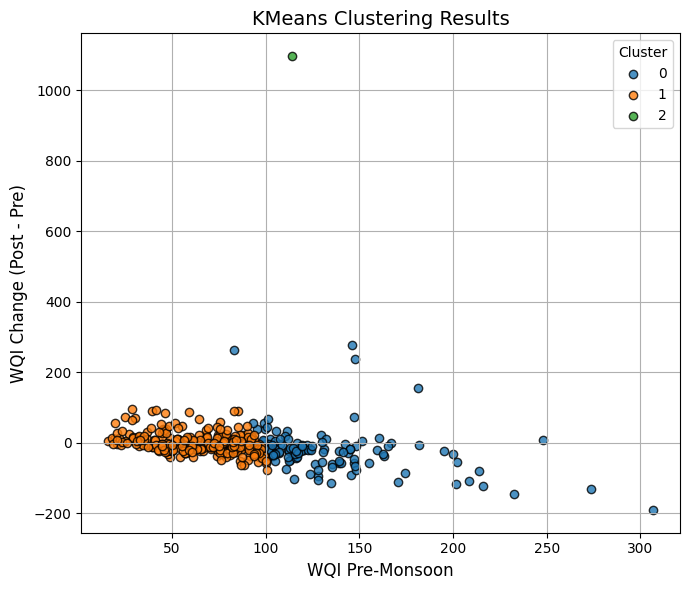

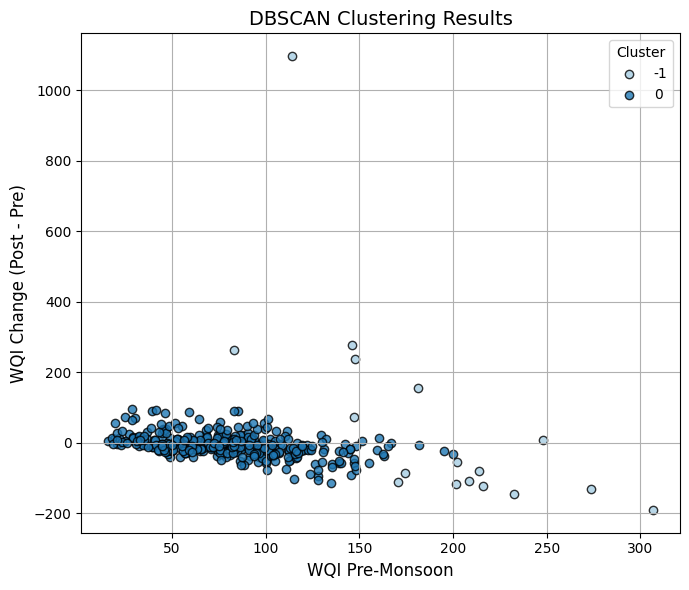

In [8]:
# Plot KMeans results with custom colors
kmeans_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
plot_scatter(df_kmeans, 'KMeans_Label', 'KMeans Clustering Results', colors=kmeans_colors)

# Plot DBSCAN results with different custom colors
dbscan_colors = ['#a6cee3', '#1f78b4', '#b2df8a', '#33a02c', '#fb9a99', '#e31a1c', '#fdbf6f', '#ff7f00']
plot_scatter(df_dbscan, 'DBSCAN_Label', 'DBSCAN Clustering Results', colors=dbscan_colors)

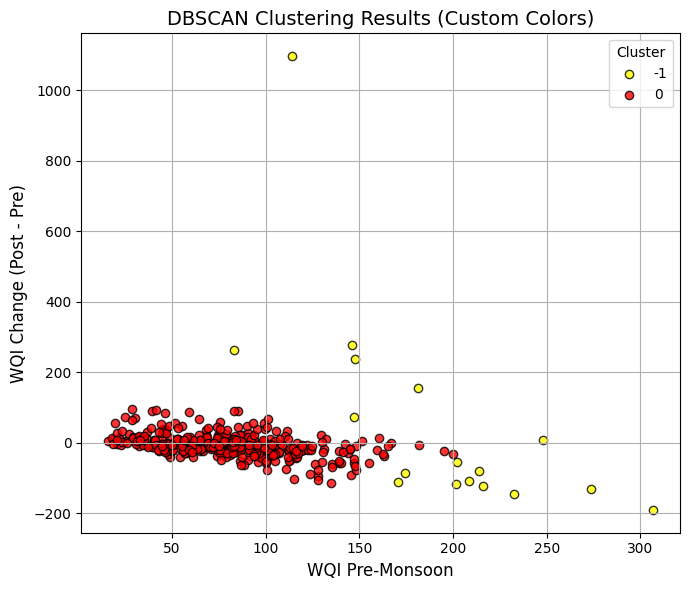

In [9]:
# Apply DBSCAN
df_dbscan = apply_dbscan(df.copy())

# Define custom colors for DBSCAN
dbscan_custom_colors = {0: 'red', 1: 'green', -1: 'yellow'}

# Plot DBSCAN results with custom colors
plot_scatter(df_dbscan, 'DBSCAN_Label', 'DBSCAN Clustering Results (Custom Colors)', colors=dbscan_custom_colors)

/tmp/ipykernel_2287/626780445.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}


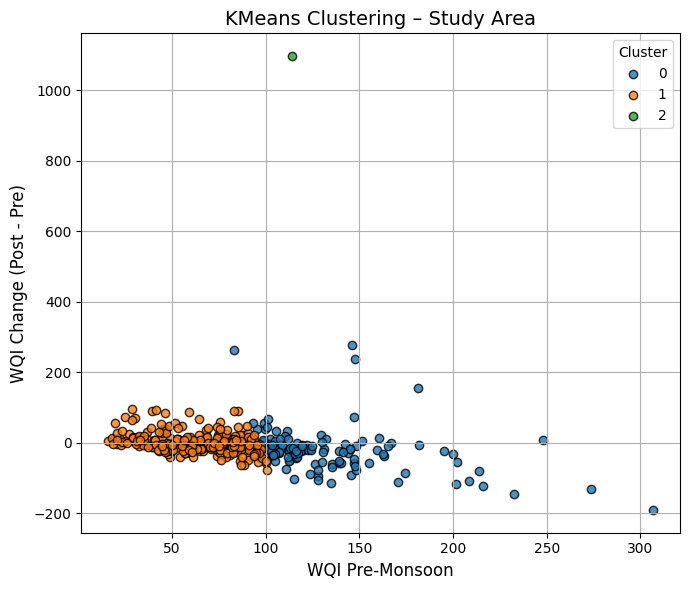

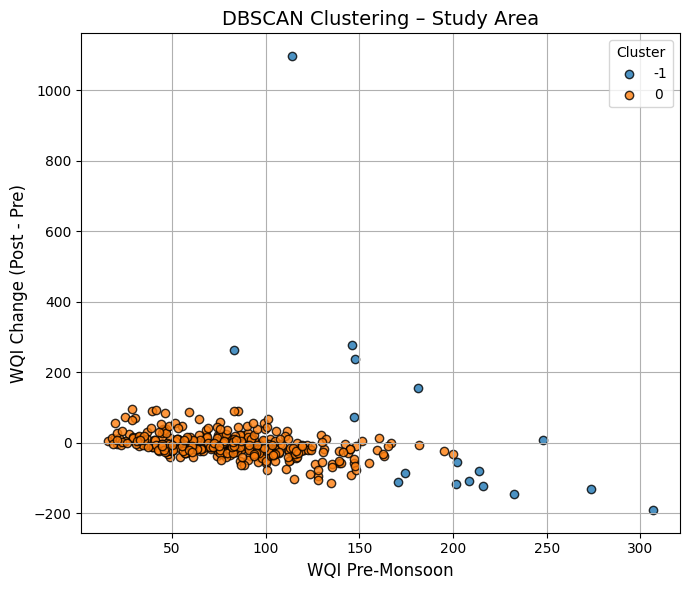


🔷 Aquifer: Alluvium


/tmp/ipykernel_2287/626780445.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}


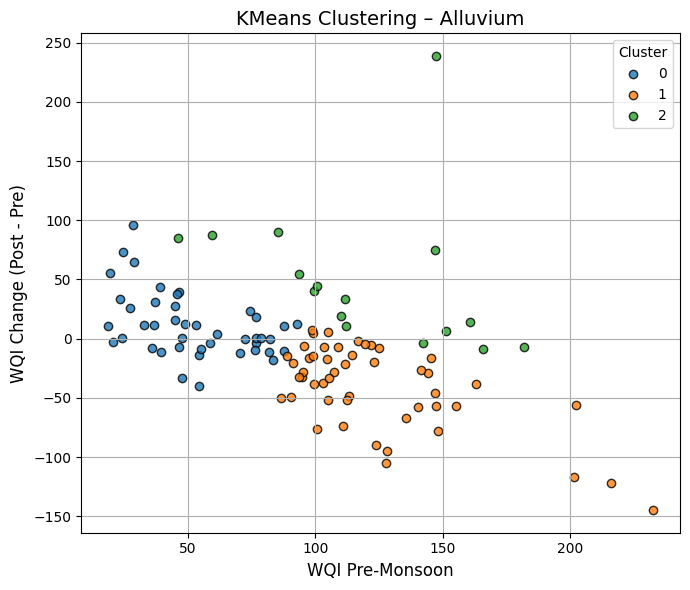

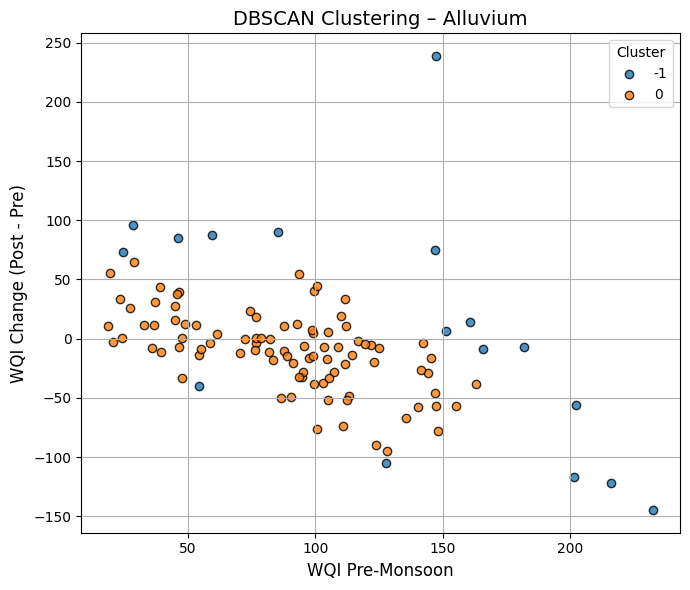


🔷 Aquifer: Cuddalore


/tmp/ipykernel_2287/626780445.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}


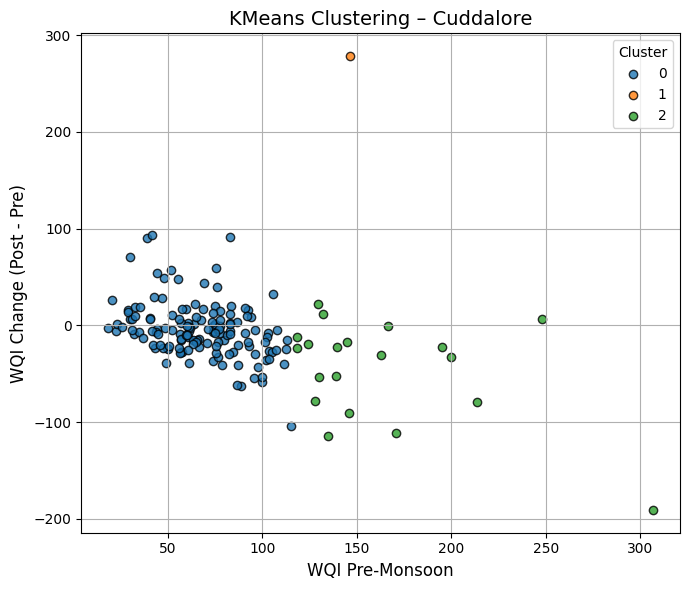

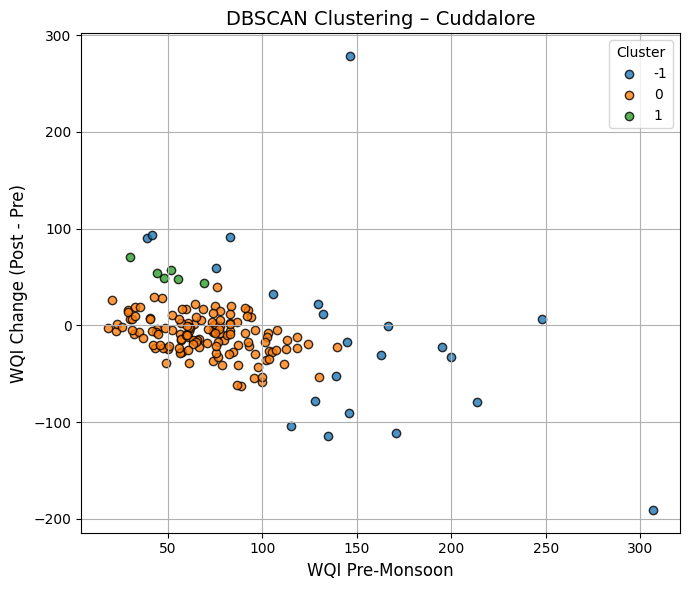


🔷 Aquifer: Kadaperikuppam


/tmp/ipykernel_2287/626780445.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}


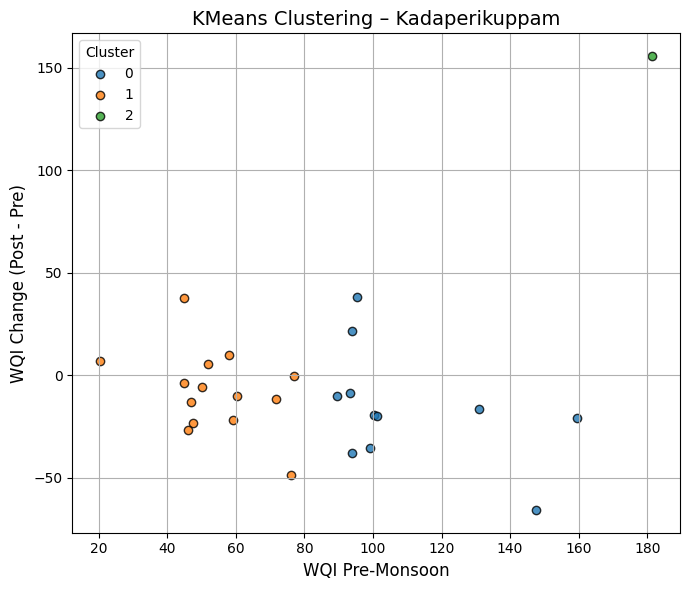

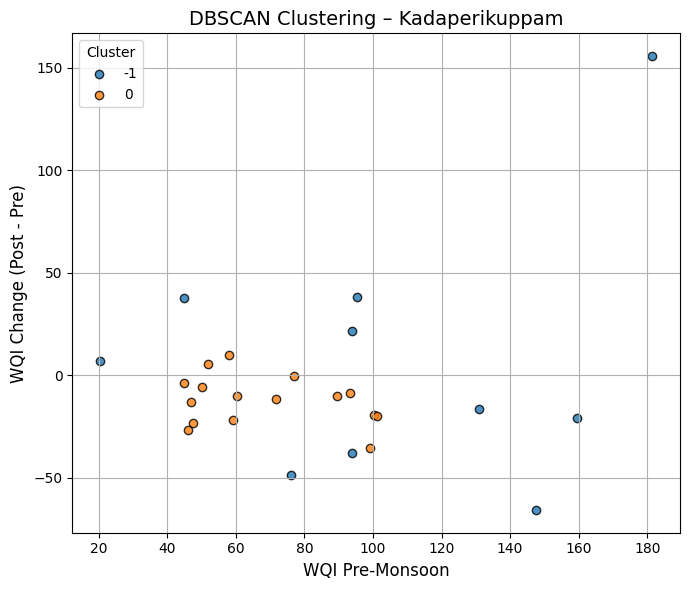


🔷 Aquifer: Vanur-Ramanathapuram


/tmp/ipykernel_2287/626780445.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}


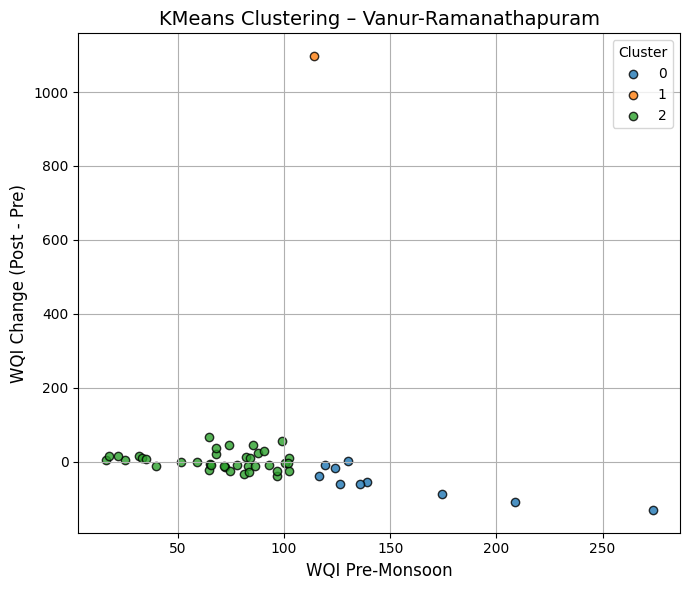

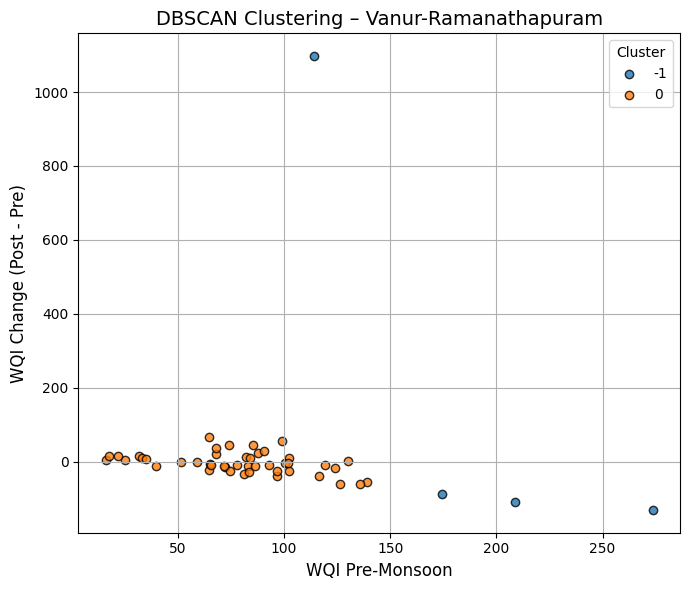


🔷 Aquifer: Thuruvai


/tmp/ipykernel_2287/626780445.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {label: plt.cm.get_cmap('tab10')(i) for i, label in enumerate(labels)}


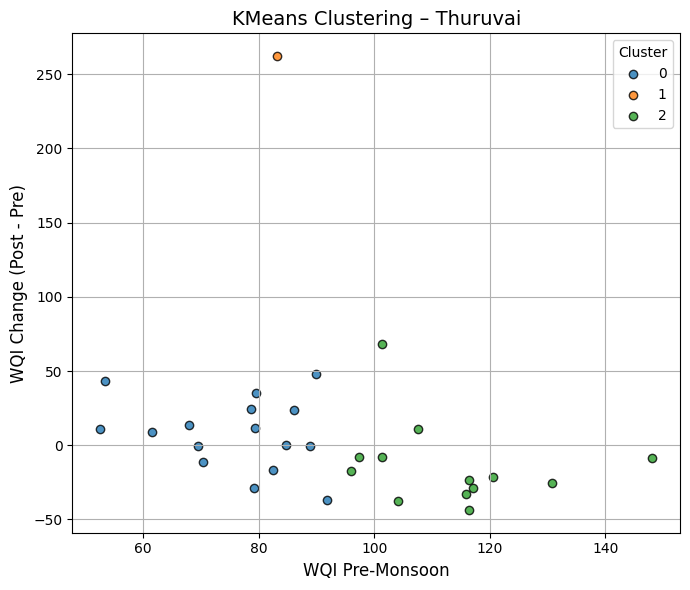

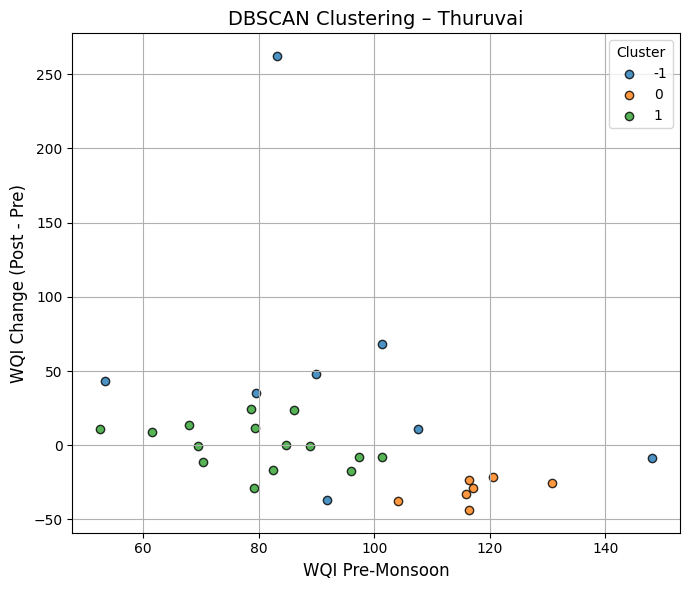

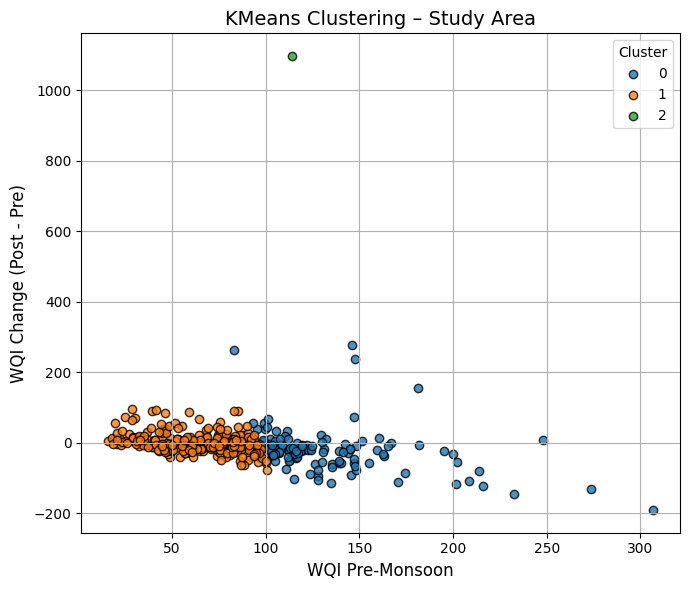

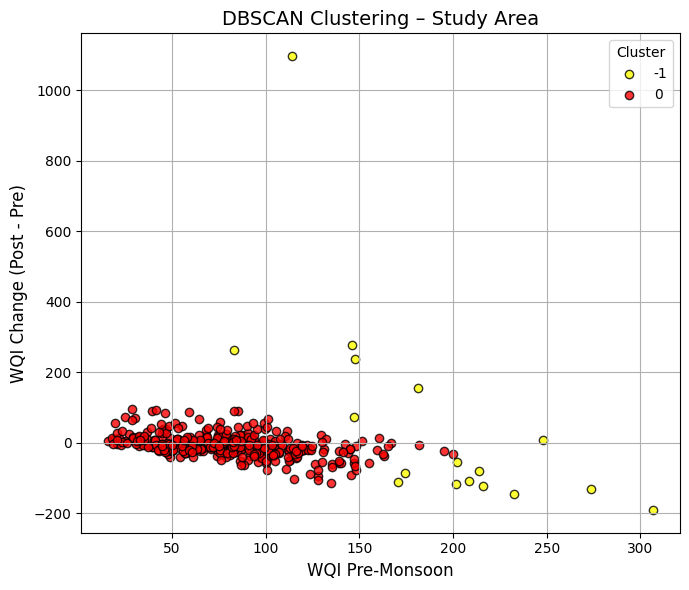

In [10]:
df = apply_kmeans(df)
df = apply_dbscan(df)
plot_scatter(df, 'KMeans_Label', "KMeans Clustering – Study Area")
plot_scatter(df, 'DBSCAN_Label', "DBSCAN Clustering – Study Area")

if 'Aquifer_ID' in df.columns:
    aquifers = df['Aquifer_ID'].unique()

    for aquifer in aquifers:
        sub_df = df[df['Aquifer_ID'] == aquifer].copy()
        sub_df = apply_kmeans(sub_df)
        sub_df = apply_dbscan(sub_df)

        print(f"\n🔷 Aquifer: {aquifer}")
        plot_scatter(sub_df, 'KMeans_Label', f"KMeans Clustering – {aquifer}")
        plot_scatter(sub_df, 'DBSCAN_Label', f"DBSCAN Clustering – {aquifer}")



# Plot KMeans results with custom colors and edge color
kmeans_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
plot_scatter(df_kmeans, 'KMeans_Label', 'KMeans Clustering – Study Area', colors=kmeans_colors)

# Plot DBSCAN results with different custom colors and edge color
dbscan_custom_colors = {0: 'red', 1: 'green', -1: 'yellow'}
plot_scatter(df_dbscan, 'DBSCAN_Label', 'DBSCAN Clustering – Study Area', colors=dbscan_custom_colors)





Generating plots for Study Area...
Plot saved to KMeans_StudyArea.png


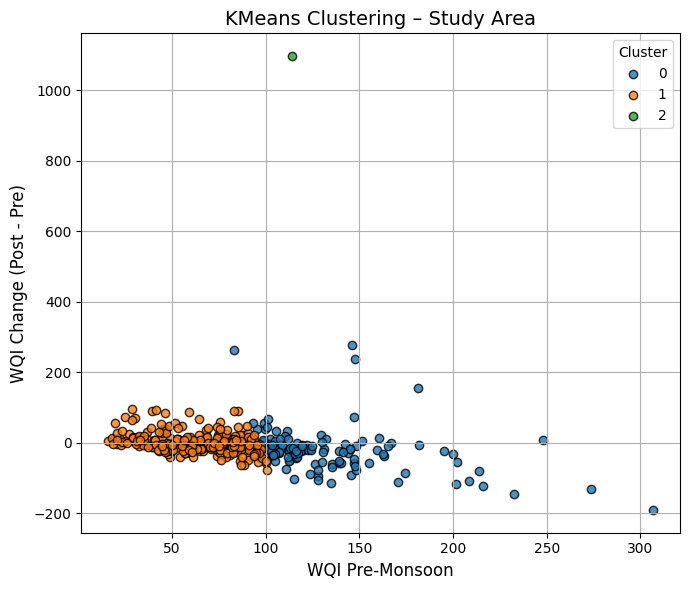

Plot saved to DBSCAN_StudyArea.png


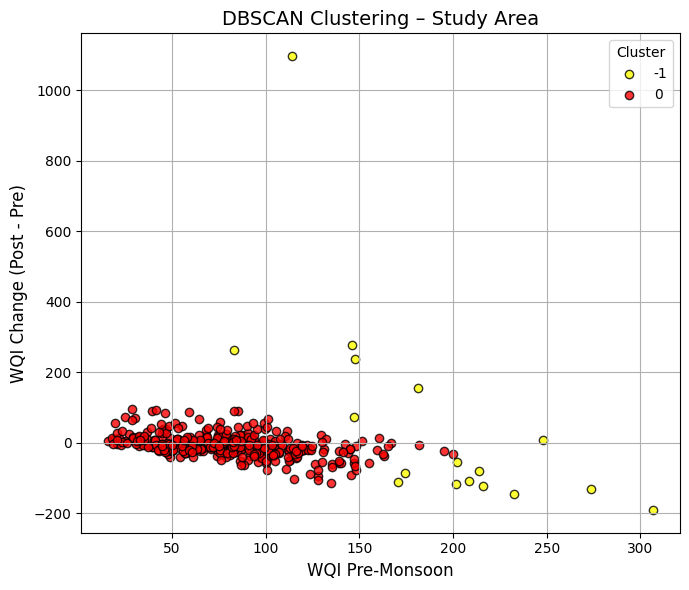


Generating plots for Aquifer: Alluvium...
Plot saved to KMeans_Alluvium.png


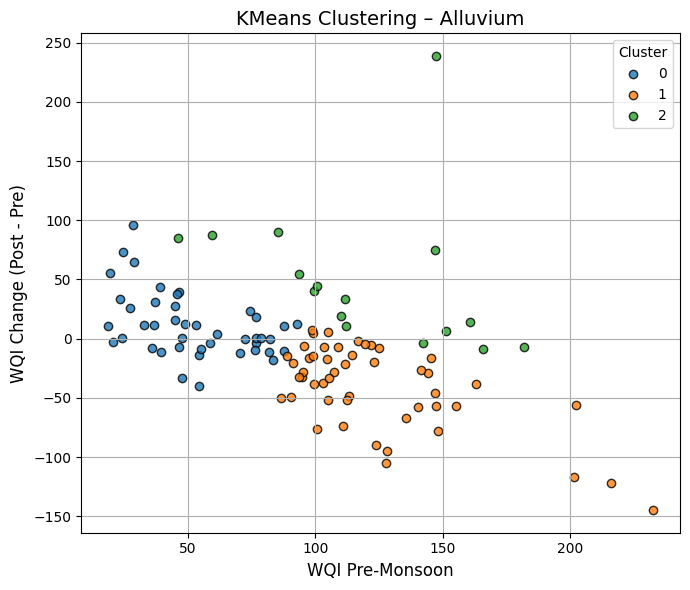

Plot saved to DBSCAN_Alluvium.png


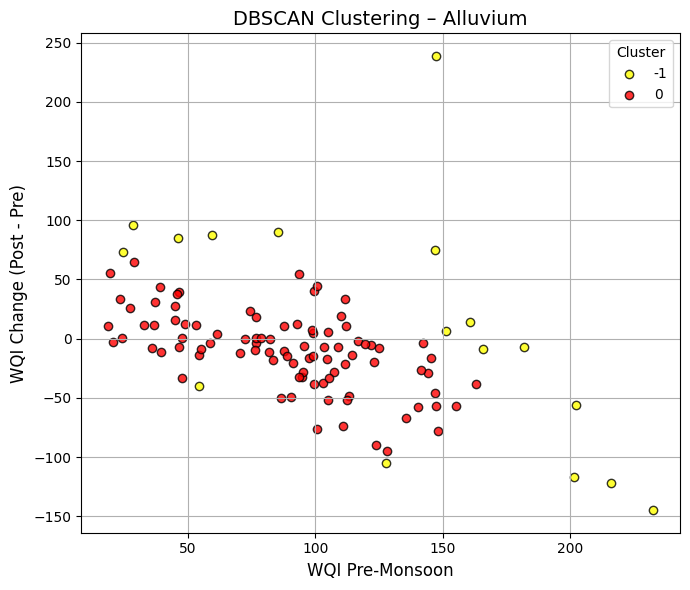


Generating plots for Aquifer: Cuddalore...
Plot saved to KMeans_Cuddalore.png


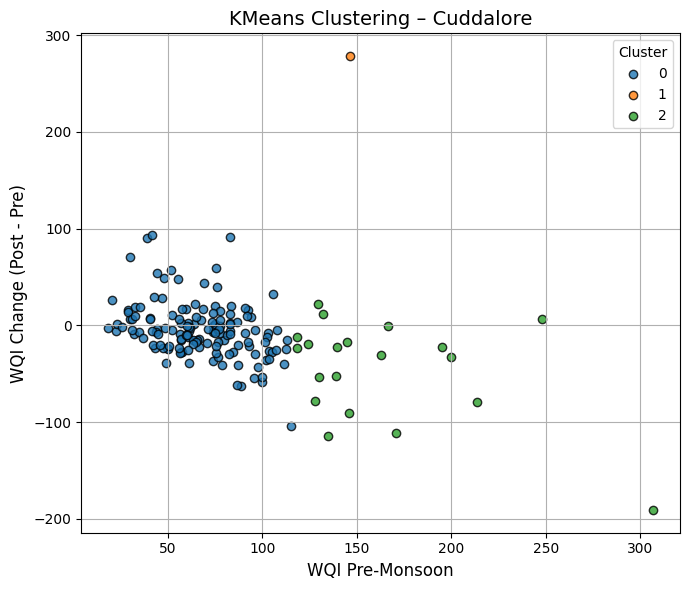

Plot saved to DBSCAN_Cuddalore.png


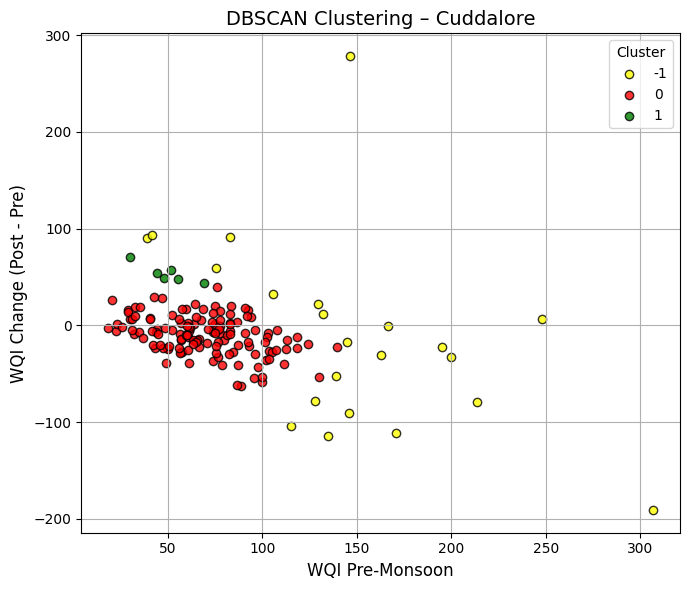


Generating plots for Aquifer: Kadaperikuppam...
Plot saved to KMeans_Kadaperikuppam.png


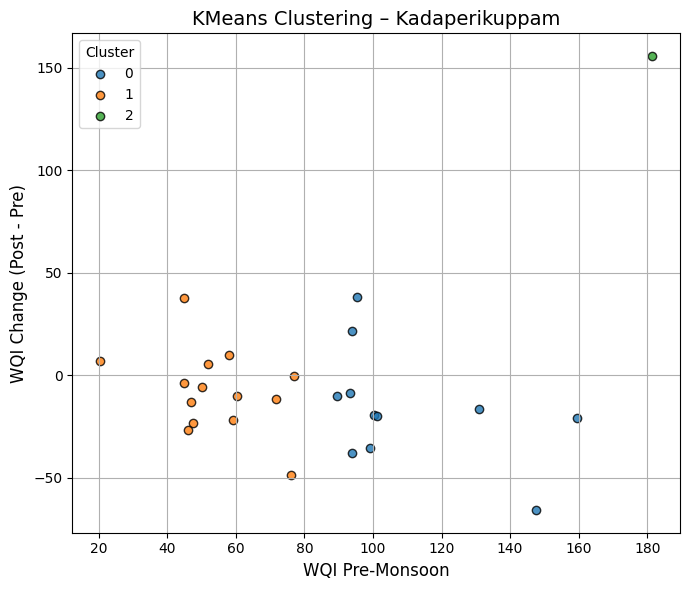

Plot saved to DBSCAN_Kadaperikuppam.png


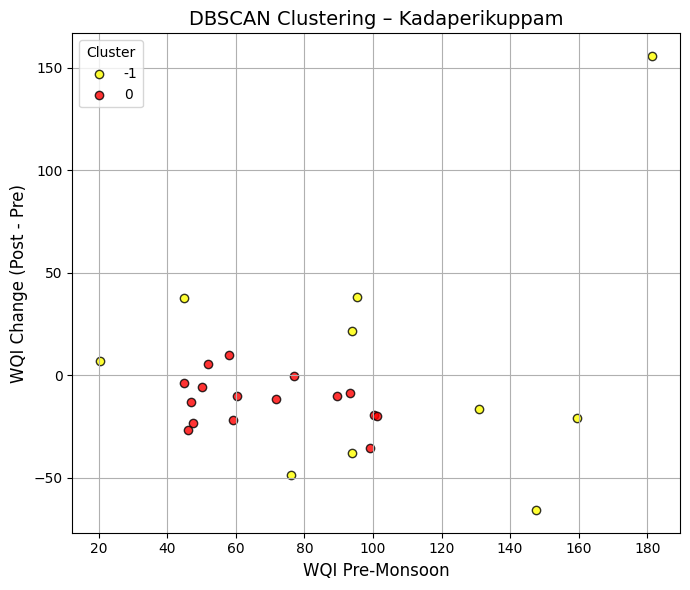


Generating plots for Aquifer: Vanur-Ramanathapuram...
Plot saved to KMeans_Vanur-Ramanathapuram.png


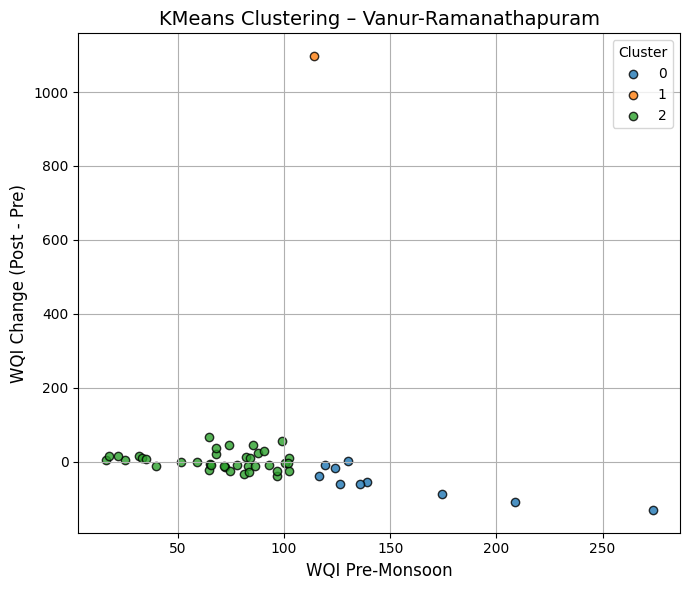

Plot saved to DBSCAN_Vanur-Ramanathapuram.png


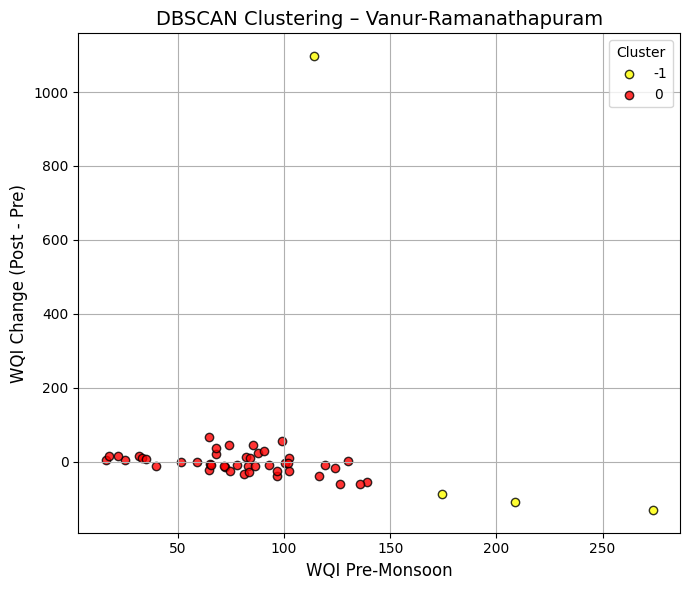


Generating plots for Aquifer: Thuruvai...
Plot saved to KMeans_Thuruvai.png


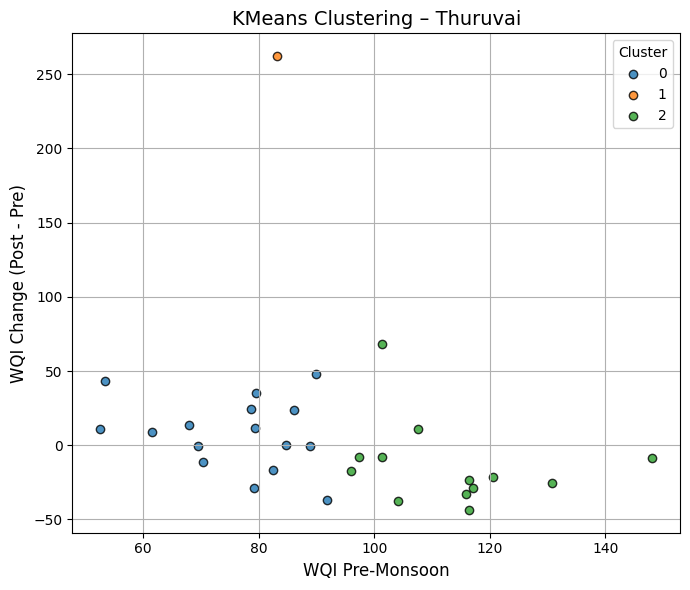

Plot saved to DBSCAN_Thuruvai.png


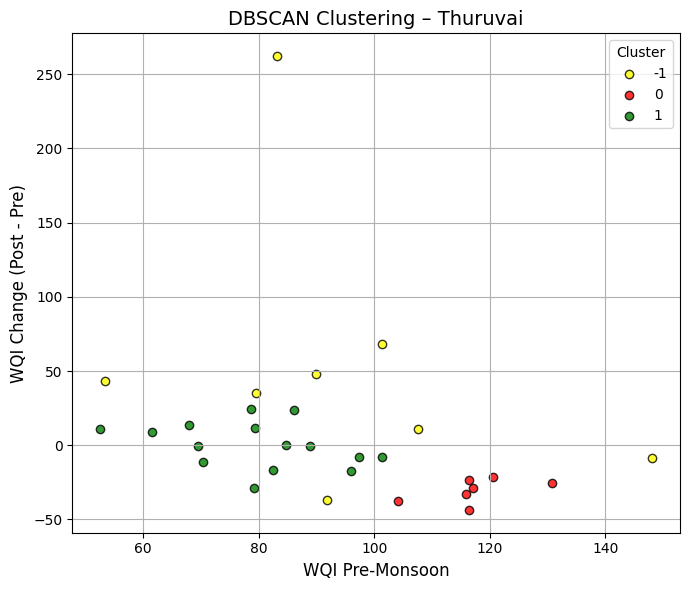


All plots generated and saved.


In [11]:
# Apply KMeans and DBSCAN to the overall study area data
df_kmeans_overall = apply_kmeans(df.copy())
df_dbscan_overall = apply_dbscan(df.copy())

# Define the custom color maps
kmeans_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
dbscan_custom_colors = {0: 'red', 1: 'green', -1: 'yellow'}

# Plot and save overall study area plots
print("Generating plots for Study Area...")
plot_scatter(df_kmeans_overall, 'KMeans_Label', 'KMeans Clustering – Study Area',
             colors=kmeans_colors, save_path='KMeans_StudyArea.png', dpi=600)
plot_scatter(df_dbscan_overall, 'DBSCAN_Label', 'DBSCAN Clustering – Study Area',
             colors=dbscan_custom_colors, save_path='DBSCAN_StudyArea.png', dpi=600)


if 'Aquifer_ID' in df.columns:
    aquifers = df['Aquifer_ID'].unique()

    for aquifer in aquifers:
        print(f"\nGenerating plots for Aquifer: {aquifer}...")
        sub_df = df[df['Aquifer_ID'] == aquifer].copy()

        # Apply KMeans and DBSCAN to the aquifer subset
        sub_df_kmeans = apply_kmeans(sub_df.copy())
        sub_df_dbscan = apply_dbscan(sub_df.copy())

        # Plot and save KMeans results for the aquifer with custom colors
        plot_scatter(sub_df_kmeans, 'KMeans_Label', f"KMeans Clustering – {aquifer}",
                     colors=kmeans_colors, save_path=f'KMeans_{aquifer}.png', dpi=600)

        # Plot and save DBSCAN results for the aquifer with custom colors
        plot_scatter(sub_df_dbscan, 'DBSCAN_Label', f"DBSCAN Clustering – {aquifer}",
                     colors=dbscan_custom_colors, save_path=f'DBSCAN_{aquifer}.png', dpi=600)

print("\nAll plots generated and saved.")